# 05 — Real data: what can a test array say about a neighbouring qubit?

**Why this notebook.** Notebooks 02–04 assume that every qubit junction is probed at room temperature.
In many processes it is not. Landing a probe on a qubit means touching its capacitor pads, so fabs probe dedicated
**test arrays** of junctions instead and use them to pick dies. A test array sees the variation shared across the wafer and the die. It cannot see the
**per-qubit** part, and that is the part that causes frequency collisions (notebook 04).

**The data (public, CC-BY 4.0).** imec's data repository for Van Damme et al., *Advanced CMOS manufacturing of
superconducting qubits on 300 mm wafers*, Nature **634**, 74–79 (2024), doi:[10.1038/s41586-024-07941-9](https://doi.org/10.1038/s41586-024-07941-9).
Dataset: J. Van Damme, Zenodo, doi:[10.5281/zenodo.13143313](https://doi.org/10.5281/zenodo.13143313) (2024), licence CC-BY 4.0.
The raw files are **not** stored in this repository; the first code cell downloads them and checks their md5 against the Zenodo record.

| File | What it holds (dataset README) |
|---|---|
| `JJ_data_full_wafer.csv` | room-temperature R and area estimate of 7872 test junctions, probed across the wafer |
| `JJ_data_three_diced_dies.csv` | more test junctions on three diced dies of the same wafer |
| `qubit_data.csv` | qubit frequency, anharmonicity, T1, … of the 393/400 functional qubits |

**What this data can and cannot tell us.** Junction positions are given **per die** (die x, y), not inside the die.
So we can measure the wafer trend, the die-to-die variation and the size of the within-die scatter. We **cannot** measure
how the correlation falls with distance *inside* a die. The README does not define the identifier tokens
(e.g. `SD05_00`, `RES-JJ-080_1`), so we do not decode them.

**Four questions.**
1. **Normalise:** use specific resistance R×A, per junction size (CD) and pooled.
2. **Variance decomposition (headline):** how much of the R×A spread is (a) a smooth wafer trend, (b) die-to-die, (c) local within-die scatter?
   Part (c) is what a test array can never see for a neighbouring qubit.
3. **Test array → qubit:** predict each qubit's frequency from its die's test arrays; split the error into a die-shared and a within-die part
   and compare the within-die part with the collision windows of Hertzberg et al. (2021), Table 1.
4. **Capacitor (E_C) scatter** from the anharmonicity, against Osman et al. (2023), 0.8%.

## Predictions, written before running (verbatim, 27 Nov 2026)

These were written after seeing only the dataset's structure (counts of files, rows, dies and sizes), before any spread was computed.

- **P1: share of the variance in ln(R×A), per CD.** I expect the trend to take 40–70%, the die-to-die residual 10–30% and within-die scatter 20–40%. I expect the within-die share to be larger at small CD (80–100 nm), since edge roughness matters more there. Pooling all CDs should lower the trend share.
- **P2: within-die σ(R×A).** I expect about 2% at large CD, anchored on Križan's 2%, and 3–5% at 80 nm. I expect (c′) from the 8 copies to agree with (c) to within a factor of 1.5.
- **P3: die-mean frequency error (leave-one-die-out).** I expect 1–2% of f, about 40–90 MHz, anchored on Fraunhofer's 1.6%.
- **P4: per-qubit within-die frequency error.** I expect 1–2% of f, or 40–90 MHz, i.e. 2–5× wider than ±17 MHz. In other words, test arrays could pick dies with a good *average* but could not predict collision-free dies.
- **P5: E_C spread within a type.** I expect 1–3% with the α ≈ −E_C approximation, which is higher than Osman's 0.8% because it includes die-to-die variation. I expect the exact correction to bring it down by under 0.5 percentage points.

*Anchors (2% RSD cited by Križan et al. 2026; 1.6% prediction error, Mayer, Weber et al. 2025; 0.8% E_C scatter, Osman et al. 2023)
are the numbers used in notebooks 02–04; see the README references.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yieldkit.imec import (load_imec, DATASET_CITATION, Z_CUT, good_junctions, decompose_by_cd, die_rn_for_qubits,
                           qubit_cq, predict_leave_one_die_out, add_design_offset_lodo, split_die_within,
                           same_design_across_dies, ec_spread, ec_die_split)
pd.set_option("display.width", 200)
print(DATASET_CITATION)
D = load_imec()
w, d, q = D["wafer"], D["diced"], D["qubits"]
print(f"wafer map : {len(w)} junctions, {w.groupby(['die_x','die_y']).ngroups} dies, CDs {[int(c) for c in sorted(w.cd_nm.unique())]} nm")
print(f"            copies per (die, CD): {[int(c) for c in w.groupby(['die_x','die_y','cd_nm']).size().unique()]}")
print(f"diced dies: {len(d)} junctions = {d.die.nunique()} dies x {len(d)//d.die.nunique()} "
      f"(dataset README: '1752 Josephson junctions on three diced dies' -- the file holds 1752 PER die)")
print(f"qubits    : {len(q)} on {q.groupby(['die_x','die_y']).ngroups} dies, {q.qtype.nunique()} types, "
      f"{q.groupby(['qtype','cd_nm']).ngroups} designs (type x nominal CD); anharmonicity missing for {q.alpha_hz.isna().sum()}")
print(f"area estimate: one value per CD in both files -> R x A is R times a constant per CD")

J. Van Damme, Advanced CMOS manufacturing of superconducting qubits on 300 mm wafers, Zenodo, doi:10.5281/zenodo.13143313 (2024), CC-BY 4.0; data for Van Damme et al., Nature 634, 74-79 (2024), doi:10.1038/s41586-024-07941-9
wafer map : 7872 junctions, 82 dies, CDs [80, 90, 100, 120, 140, 160, 180, 200, 220, 240, 280, 320] nm
            copies per (die, CD): [8]
diced dies: 5256 junctions = 3 dies x 1752 (dataset README: '1752 Josephson junctions on three diced dies' -- the file holds 1752 PER die)
qubits    : 393 on 36 dies, 5 types, 15 designs (type x nominal CD); anharmonicity missing for 7
area estimate: one value per CD in both files -> R x A is R times a constant per CD


## 1. Normalise: specific resistance R×A, and gross failures

Resistance mostly reflects junction size: an 80 nm junction has about 5× the resistance of a 320 nm one. Multiplying by the area
gives the **specific resistance R×A**, which depends only on the tunnel barrier (and on how far the real area differs from the estimate).
We analyse ln(R×A), so a spread of 0.05 reads as about 5%.

The files contain **failed junctions**: opens (R up to 10³⁰ Ω) and shorts. The dataset defines no exclusion rule, so we use our own,
**labelled choice**: drop a junction if ln(R×A) lies more than **10 robust σ** (σ = 1.4826 × median absolute deviation) from its CD group's median.
Section 2 repeats the analysis with a 5σ cut.

In [2]:
cnt = pd.DataFrame({
    "wafer kept": w[good_junctions(w)].groupby("cd_nm").size(),
    "wafer dropped": w[~good_junctions(w)].groupby("cd_nm").size(),
    "diced kept": d[good_junctions(d)].groupby("cd_nm").size(),
    "diced dropped": d[~good_junctions(d)].groupby("cd_nm").size(),
}).fillna(0).astype(int)
cnt.loc["all"] = cnt.sum()
print(f"Gross-failure cut: {Z_CUT:.0f} robust sigma")
cnt

Gross-failure cut: 10 robust sigma


,wafer kept,wafer dropped,diced kept,diced dropped
cd_nm,,,,
80,642,14,433,5
90,632,24,435,3
100,636,20,434,4
120,644,12,433,5
140,644,12,434,4
160,643,13,435,3
180,643,13,434,4
200,643,13,431,7
220,639,17,434,4


## 2. Variance decomposition: trend, die-to-die, within-die

For each CD group:
* **(a) wafer trend**: a smooth 2nd-order polynomial in die (x, y) (6 terms), fitted to the die means;
* **(b) die-to-die residual**: what is left in the die means after the trend, minus the part that is just within-die noise averaged over 8 copies
  (one-way ANOVA, the same estimator as notebook 04);
* **(c) within-die scatter** from the 3 diced dies (junctions spread over the whole die), and as a cross-check
  **(c′)** the scatter among the 8 copies of each CD on every wafer-map die.

Shares are (a), (b), (c) as fractions of their sum. The **pooled** row removes each CD group's mean first.

In [3]:
dec = decompose_by_cd(w, d)
show = dec[["n_wafer", "n_diced", "sigma_trend", "sigma_die", "sigma_within_diced", "sigma_within_copies",
            "share_trend", "share_die", "share_within"]].copy()
for c in ["sigma_trend", "sigma_die", "sigma_within_diced", "sigma_within_copies"]:
    show[c] = (show[c] * 100).round(1)
for c in ["share_trend", "share_die", "share_within"]:
    show[c] = (show[c] * 100).round(0).astype(int)
show.columns = ["n wafer", "n diced", "σ trend %", "σ die %", "σ within (c) %", "σ copies (c′) %",
                "trend share %", "die share %", "within share %"]
show

,n wafer,n diced,σ trend %,σ die %,σ within (c) %,σ copies (c′) %,trend share %,die share %,within share %
cd_nm,,,,,,,,,
80,642,433,13.7,1.3,16.2,13.5,42,0,58
90,632,435,11.6,8.7,13.5,16.7,34,19,46
100,636,434,11.1,2.4,11.6,11.6,47,2,51
120,644,433,10.3,0.4,10.4,9.7,50,0,50
140,644,434,10.4,1.3,9.5,8.4,54,1,45
160,643,435,9.4,0.0,9.9,8.0,47,0,53
180,643,434,8.8,0.7,8.6,7.3,51,0,49
200,643,431,8.3,0.0,8.1,7.4,51,0,49
220,639,434,8.0,0.0,8.1,6.1,49,0,51


In [4]:
sens = pd.DataFrame({
    "within share %, 2nd-order trend, 10σ cut": decompose_by_cd(w, d)["share_within"] * 100,
    "within share %, 2nd-order trend, 5σ cut": decompose_by_cd(w, d, z_cut=5)["share_within"] * 100,
    "within share %, 1st-order trend, 10σ cut": decompose_by_cd(w, d, order=1)["share_within"] * 100,
    "die share %, 1st-order trend, 10σ cut": decompose_by_cd(w, d, order=1)["share_die"] * 100,
}).round(0).astype(int)
sens

,"within share %, 2nd-order trend, 10σ cut","within share %, 2nd-order trend, 5σ cut","within share %, 1st-order trend, 10σ cut","die share %, 1st-order trend, 10σ cut"
cd_nm,,,,
80,58,45,57,40
90,46,50,47,51
100,51,51,51,48
120,50,49,50,48
140,45,43,44,54
160,53,42,53,45
180,49,45,48,50
200,49,46,48,50
220,51,46,51,47


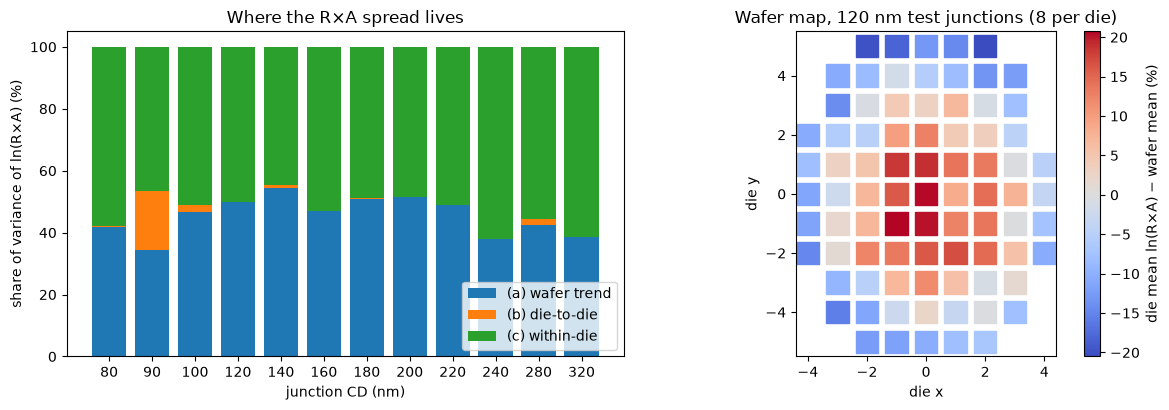

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
per = dec.drop(index="pooled")
x = np.arange(len(per))
b0 = per.share_trend * 100; b1 = per.share_die * 100; b2 = per.share_within * 100
ax[0].bar(x, b0, label="(a) wafer trend"); ax[0].bar(x, b1, bottom=b0, label="(b) die-to-die")
ax[0].bar(x, b2, bottom=b0 + b1, label="(c) within-die")
ax[0].set_xticks(x, per.index); ax[0].set_xlabel("junction CD (nm)"); ax[0].set_ylabel("share of variance of ln(R×A) (%)")
ax[0].legend(loc="lower right"); ax[0].set_title("Where the R×A spread lives")
cd0 = 120
g = w[good_junctions(w) & (w.cd_nm == cd0)]
m = g.assign(y=np.log(g.ra_ohm_m2)).groupby(["die_x", "die_y"]).y.mean().reset_index()
sc = ax[1].scatter(m.die_x, m.die_y, c=(m.y - m.y.mean()) * 100, s=260, marker="s", cmap="coolwarm")
plt.colorbar(sc, ax=ax[1], label="die mean ln(R×A) − wafer mean (%)")
ax[1].set_xlabel("die x"); ax[1].set_ylabel("die y"); ax[1].set_aspect("equal")
ax[1].set_title(f"Wafer map, {cd0} nm test junctions (8 per die)")
plt.tight_layout(); plt.show()

**What actually happened (section 2).**

* **About half of the R×A variance is local, within-die scatter**: 45–62% per CD, 55% pooled. This holds with a 5σ cut (42–56%) and with a 1st-order trend (44–62%).
* **The other half is a smooth, bowl-shaped wafer pattern.** With a 2nd-order trend, the die-to-die residual is close to zero (0–2% of the variance; 19% at 90 nm only). With a 1st-order (planar) trend, the die-to-die share jumps to 36–54%. A plane cannot follow the bowl, so the bowl is the variation. In other words, after a smooth radial fit, dies hardly differ from one another.
* **The local scatter is large**: σ of ln(R×A) within a die is 8–10% at 140–320 nm, rising to 12–16% at 80–100 nm (diced dies). The 8 copies on each wafer-map die scatter almost as much (6–17%). Neighbouring test junctions disagree about as much as junctions spread over the whole die. So at the scales this data can see, the local scatter looks like **independent junction-to-junction noise**, not a smooth pattern.
* The wafer bowl itself spans σ ≈ 7–14% (larger at small CD).

## 3. Test array → qubit (wedge 1)

**Prediction for each qubit, from its die's test arrays only.**
1. Junction resistance: the die-mean ln(R×A) of each CD group, interpolated to the qubit's nominal CD, divided by the area estimate
   interpolated to that CD. **Assumption:** a qubit junction of nominal CD behaves like a test junction of the same CD.
2. Frequency: Ambegaokar–Baratoff → E_J; E_C from a capacitance per qubit type; f01 from the **exact** transmon spectrum (notebook 01).
   The capacitance per type is the median of each qubit's C_q found from its measured (f01, α) by exact diagonalisation.
   The dataset gives no design capacitance, so this stands in for it (**labelled**).
3. Effective T_c is fitted by least squares as in notebook 04 (Lang et al. 2025). **Leave-one-die-out:** each die is predicted with T_c and the
   per-type C_q fitted on the other dies only.
   T_c here is **effective**: the qubit sees its *cold* junction resistance, R_cold = k·R_RT, and E_J ∝ T_c / (k·R_RT), so a T_c
   fitted on room-temperature data is T_c/k (times any area or geometry error). k cannot be fitted separately from T_c.
   Example k = 1.1375 for Chalmers junctions (Križan, PhD thesis, Chalmers 2026, p. 49; "not universal", p. 76).

**Design-specific prediction.** No qubit design (type × nominal CD) repeats on a die, so "qubit minus die mean" on raw frequencies would
compare different designs. Instead we use each qubit's **residual** = measured − its own design-specific prediction, where the
design-specific prediction adds that design's mean residual **from the other dies** (it absorbs fixed model bias such as a wrong area or C_q,
and a per-design cold/warm resistance ratio k; strictly k is a scale, but fitting T_c per design instead changes the split below by
only ~4 MHz).
Then, as in notebook 04:
* **die-shared part** = mean residual of that die's qubits;
* **within-die part** = residual − that mean.

Only dies with at least 2 working qubits are used. A second, independent estimate of the die-shared part uses the **same design on
different dies**: after removing each design's mean, two different qubits on the same die share only the die effect, so the average product
over same-die pairs estimates σ_die².

In [6]:
cq_each = qubit_cq(q)
rn_pred = die_rn_for_qubits(w, q)
p = predict_leave_one_die_out(q, rn_pred, cq_each)
p = add_design_offset_lodo(p)
print(f"qubits with test-array data on their die: {len(p)} of {len(q)} "
      f"(die(s) without test data: {sorted(set(zip(q.die_x, q.die_y)) - set(zip(w.die_x, w.die_y)))})")
print(f"fitted effective Tc (leave-one-die-out): median {p.tc_fit_k.median():.3f} K, range {p.tc_fit_k.min():.3f}–{p.tc_fit_k.max():.3f} K")
by = p.groupby("design").agg(n=("f01_hz", "size"), f_GHz=("f01_hz", lambda v: v.mean() / 1e9),
                             raw_bias_MHz=("resid_hz", lambda v: v.mean() / 1e6),
                             spread_across_dies_MHz=("resid_hz", lambda v: v.std() / 1e6),
                             spread_rel_pct=("resid_hz", lambda v: (v / p.loc[v.index, 'f01_hz']).std() * 100))
by.round(2)

qubits with test-array data on their die: 389 of 393 (die(s) without test data: [(4, 2)])
fitted effective Tc (leave-one-die-out): median 1.126 K, range 1.120–1.131 K


,n,f_GHz,raw_bias_MHz,spread_across_dies_MHz,spread_rel_pct
design,,,,,
imon_w13_g13|120nm,31,4.63,-260.72,469.01,8.74
imon_w24_g24|110nm,31,4.26,-391.41,311.87,7.20
imon_w48_g48|100nm,31,4.02,-418.41,284.12,7.74
imon_w90_g90|110nm,30,6.06,1495.45,377.47,5.07
imon_w90_g90|90nm,27,3.67,-358.01,268.08,7.81
xmon_w20_g13|100nm,24,4.26,-207.65,240.55,5.84
xmon_w20_g13|110nm,24,4.57,-165.14,277.38,6.01
xmon_w20_g13|120nm,24,4.82,-178.03,199.32,4.24
xmon_w20_g13|121nm,24,6.74,1711.78,277.31,3.05


Two designs sit about **1.5–1.7 GHz above** the chain prediction (xmon at 121 nm, imon_w90 at 110 nm). Their neighbours at 120 nm and 90 nm do not,
so a nominal CD does not fix the junction geometry of every design. This is exactly the fixed model bias the design-specific offset absorbs.
The other designs are biased by a few hundred MHz, largely because one global T_c has to fit those two designs as well.

In [7]:
ok = p[np.isfinite(p.resid_design_hz)]
split = split_die_within(ok.resid_design_hz, ok.die, min_per_die=2)
raw_split = split_die_within(ok.resid_hz, ok.die, min_per_die=2)
same = same_design_across_dies(ok.resid_hz, ok.die, ok.design)
n_q = ok.die.value_counts()
print(f"dies with >= 2 working qubits (and test data): {split['n_dies']} of {ok.die.nunique()}; qubits used: {split['n_qubits']}; "
      f"qubits per die: {sorted(int(v) for v in n_q.unique())}")
print()
print("Design-specific residuals (measured - design-specific prediction):")
print(f"  die-shared part   sigma_die    = {split['sigma_die']/1e6:6.0f} MHz   (die-mean split)")
print(f"  die-shared part   sigma_die    = {same['sigma_die_pairs']/1e6:6.0f} MHz   (same-die pairs of different designs, {same['n_pairs']} pairs; independent)")
print(f"  within-die part   sigma_within = {split['sigma_within']/1e6:6.0f} MHz   "
      f"({(split['within']/ok.loc[split['within'].index,'f01_hz']).std()*100:.1f}% of f)")
print(f"  same design across dies        = {same['sigma_design_across_dies']/1e6:6.0f} MHz   "
      f"(should be ~ sqrt(die^2 + within^2) = {np.hypot(split['sigma_die'], split['sigma_within'])/1e6:.0f} MHz)")
print(f"Without the design offset (raw): within-die {raw_split['sigma_within']/1e6:.0f} MHz -- design biases leak in, as expected.")
wi = split["within"].abs() / 1e6
print()
print("Within-die part vs Hertzberg et al. 2021 Table 1 windows (yardstick only: these imec chips are not laid out against collisions,")
print("and Table 1 assumes alpha = -330 MHz):")
for b, name in ((4, "type 2, ±4 MHz"), (17, "types 1/5/7, ±17 MHz"), (30, "type 3, ±30 MHz")):
    print(f"  {name:22s}: window / sigma_within = {b/(split['sigma_within']/1e6):.2f};  {np.mean(wi < b)*100:4.1f}% of qubits inside")

dies with >= 2 working qubits (and test data): 35 of 35; qubits used: 389; qubits per die: [4, 5, 10, 14, 15]

Design-specific residuals (measured - design-specific prediction):
  die-shared part   sigma_die    =    120 MHz   (die-mean split)
  die-shared part   sigma_die    =    125 MHz   (same-die pairs of different designs, 2316 pairs; independent)
  within-die part   sigma_within =    274 MHz   (5.2% of f)
  same design across dies        =    295 MHz   (should be ~ sqrt(die^2 + within^2) = 299 MHz)
Without the design offset (raw): within-die 723 MHz -- design biases leak in, as expected.

Within-die part vs Hertzberg et al. 2021 Table 1 windows (yardstick only: these imec chips are not laid out against collisions,
and Table 1 assumes alpha = -330 MHz):
  type 2, ±4 MHz        : window / sigma_within = 0.01;   1.5% of qubits inside
  types 1/5/7, ±17 MHz  : window / sigma_within = 0.06;   4.6% of qubits inside
  type 3, ±30 MHz       : window / sigma_within = 0.11;   9.5% of qubits

**Is the within-die error just junction scatter?** If a qubit junction is one more draw from the same distribution as the test junctions,
its resistance scatters by the within-die σ of ln(R×A) at its CD, and its frequency by
δf ≈ (f + E_C)/2 × δln R (from f = √(8E_JE_C) − E_C, notebook 01). We compute that expectation qubit by qubit from both within-die estimates.

In [8]:
sig_c = dec.drop(index="pooled")["sigma_within_diced"]; sig_c.index = sig_c.index.astype(int)
sig_cp = dec.drop(index="pooled")["sigma_within_copies"]; sig_cp.index = sig_cp.index.astype(int)
ec_hz = 1.602176634e-19**2 / (2 * ok.cq_type_f) / 6.62607015e-34
for name, s in (("(c) diced dies", sig_c), ("(c') 8 copies", sig_cp)):
    s_at = np.interp(ok.cd_nm, s.index.to_numpy(), s.to_numpy())
    exp = np.sqrt(np.mean(((ok.f01_hz + ec_hz) / 2 * s_at) ** 2))
    print(f"expected per-qubit sigma from test-junction scatter {name}: {exp/1e6:4.0f} MHz   (measured within-die: {split['sigma_within']/1e6:.0f} MHz)")

expected per-qubit sigma from test-junction scatter (c) diced dies:  279 MHz   (measured within-die: 274 MHz)
expected per-qubit sigma from test-junction scatter (c') 8 copies:  272 MHz   (measured within-die: 274 MHz)


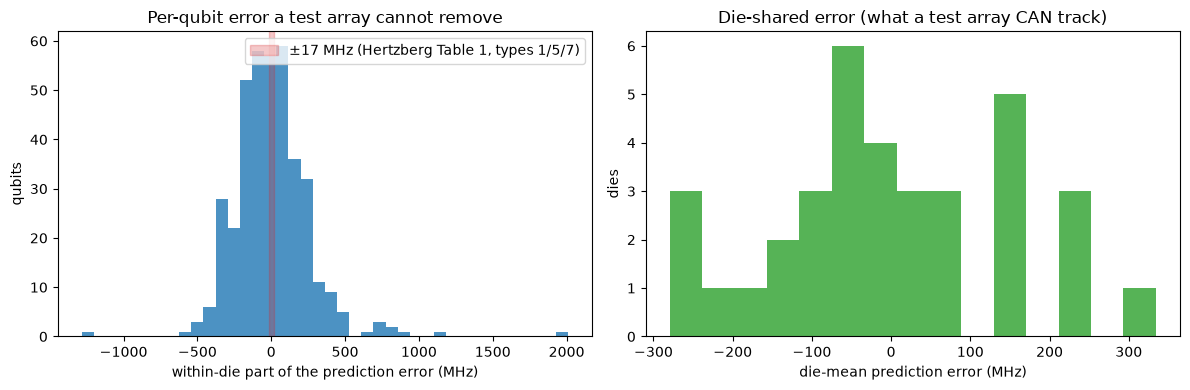

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(split["within"] / 1e6, bins=40, color="tab:blue", alpha=0.8)
ax[0].axvspan(-17, 17, color="tab:red", alpha=0.25, label="±17 MHz (Hertzberg Table 1, types 1/5/7)")
ax[0].set_xlabel("within-die part of the prediction error (MHz)"); ax[0].set_ylabel("qubits"); ax[0].legend()
ax[0].set_title("Per-qubit error a test array cannot remove")
dm = ok.groupby("die").agg(r=("resid_design_hz", "mean"))
ax[1].hist(dm.r / 1e6, bins=15, color="tab:green", alpha=0.8)
ax[1].set_xlabel("die-mean prediction error (MHz)"); ax[1].set_ylabel("dies")
ax[1].set_title("Die-shared error (what a test array CAN track)")
plt.tight_layout(); plt.show()

**What actually happened (section 3).**

* **35 dies qualify** (≥ 2 working qubits and test-array data; 4–15 qubits per die; 389 qubits). That is enough for the die-level estimate to mean something, though it is still one wafer.
* **Die-shared part:** σ ≈ **120 MHz** from the die-mean split and **125 MHz** from same-die pairs of different designs. The two estimates are independent, and they agree.
* **Within-die, per-qubit part:** σ ≈ **274 MHz (5.2% of f)**. The same design across dies scatters by 295 MHz, consistent with √(120² + 274²) = 299 MHz.
* **The per-qubit error is exactly the test-junction scatter.** Treating each qubit junction as one more draw from the test junctions of its CD predicts 279 MHz (diced dies) or 272 MHz (copies), against 274 MHz measured. Nothing else is needed to explain it.
* **Against the collision windows:** ±17 MHz is 0.06 σ wide, and only 4.6% of qubits land inside it by chance (1.5% for ±4 MHz, 9.5% for ±30 MHz).
* Fitted effective T_c ≈ 1.13 K. It is an *effective* parameter, T_c/k with k = R_cold/R_RT, and also absorbs the area estimate and the qubit-vs-test geometry; it is not comparable with Fraunhofer's 0.71 K.

## 4. Capacitor (E_C) scatter (wedge 3)

The anharmonicity gives the charging energy almost directly, but **α ≈ −E_C** (Koch et al. 2007) is only the leading term: |α| is a few % larger
and depends weakly on E_J. **Primary method:** find C_q from the measured (f01, α) by exact diagonalisation (as above).
**Cross-check:** solve the closed-form series for f01 (Eq. 4.3) and α (Eq. 4.11) of Križan's PhD thesis (Chalmers 2026) jointly for E_J and E_C.
Both remove the part of the α spread that comes from E_J; the old α ≈ −E_C figure is printed only for comparison.
We report it per qubit type (as asked) and per design, because two types contain two different devices (see section 3).
Then, after removing each design's mean, we split ln E_C into a die-shared and a within-die part. We compare with
Osman et al. (2023): σ_EC = 0.8% over 32 identical qubits on 4 dies.

*Caveat:* the dataset gives no uncertainty for α; any fitting noise in α adds to this spread.

In [10]:
t1 = ec_spread(p, "qtype"); t2 = ec_spread(p, "design")
names = {"rsd_exact": "E_C spread % (exact)", "rsd_eq411": "E_C spread % (Eq. 4.11)",
         "ec_eq411_minus_exact_pct": "E_C(4.11) − E_C(exact), %"}
t1, t2 = [(t.assign(rsd_exact=t.rsd_exact * 100, rsd_eq411=t.rsd_eq411 * 100).rename(columns=names).round(3)) for t in (t1, t2)]
display(t1); display(t2)
es = ec_die_split(p)
for k, label in (("exact", "exact"), ("eq411", "Eq. 4.11"), ("approx", "α≈−E_C (replaced)")):
    e = es[k]
    print(f"{label:18s}: design-centred E_C spread {e['rsd_total_design_centred']*100:.2f}%  ->  within-die {e['rsd_within_die']*100:.2f}%, "
          f"die-shared {e['rsd_die']*100:.2f}%   ({e['n_dies']} dies with >= 2 qubits, {e['n_qubits']} qubits)")
print("Osman et al. 2023: 0.8%")

,n,alpha_mean_mhz,ec_mean_mhz,E_C spread % (exact),E_C spread % (Eq. 4.11),"E_C(4.11) − E_C(exact), %"
qtype,,,,,,
imon_w13_g13,30,-229.121,204.243,2.215,2.226,0.047
imon_w24_g24,31,-234.847,206.853,1.514,1.534,0.073
imon_w48_g48,30,-244.653,212.393,1.805,1.845,0.119
imon_w90_g90,56,-220.014,196.102,5.557,5.631,0.078
xmon_w20_g13,235,-247.150,220.712,2.630,2.653,0.052


,n,alpha_mean_mhz,ec_mean_mhz,E_C spread % (exact),E_C spread % (Eq. 4.11),"E_C(4.11) − E_C(exact), %"
design,,,,,,
imon_w13_g13|120nm,30,-229.121,204.243,2.215,2.226,0.047
imon_w24_g24|110nm,31,-234.847,206.853,1.514,1.534,0.073
imon_w48_g48|100nm,30,-244.653,212.393,1.805,1.845,0.119
imon_w90_g90|110nm,29,-201.200,186.381,2.699,2.704,0.008
imon_w90_g90|90nm,27,-240.221,206.543,1.123,1.165,0.153
xmon_w20_g13|100nm,24,-258.077,224.578,0.939,0.954,0.106
xmon_w20_g13|110nm,24,-254.152,223.757,0.968,0.988,0.073
xmon_w20_g13|120nm,24,-251.391,223.102,0.811,0.822,0.055
xmon_w20_g13|121nm,22,-229.462,212.262,2.068,2.070,0.008


exact             : design-centred E_C spread 2.03%  ->  within-die 1.90%, die-shared 0.81%   (35 dies with >= 2 qubits, 382 qubits)
Eq. 4.11          : design-centred E_C spread 2.04%  ->  within-die 1.91%, die-shared 0.83%   (35 dies with >= 2 qubits, 382 qubits)
α≈−E_C (replaced) : design-centred E_C spread 2.75%  ->  within-die 2.35%, die-shared 1.65%   (35 dies with >= 2 qubits, 382 qubits)
Osman et al. 2023: 0.8%


**What actually happened (section 4).**

* **Per design**, the E_C spread is 0.7–3.4% exact (1.5–3.8% with α ≈ −E_C). **Per type** it is 1.5–5.6% exact (2.6–9.4% approximate). The type numbers are inflated where a type mixes two devices (imon_w90 at 90 and 110 nm).
* **With each design's mean removed:** 2.0% exact (2.75% approximate). It is mostly **within-die (1.9%)**, with a die-shared part of 0.8%.
* That is **about 2.5× Osman's 0.8%**. Two caveats: the dataset gives no uncertainty on α, so fitting noise would inflate this, which makes it an upper bound; and it is a different process.
* The exact correction matters more than expected. It lowers the per-design spread by 0.4–1.4 points, and the design-centred spread by 0.7 points. The mean |α| is about 1.12 × E_C and depends weakly on E_J. The junction scatter on this wafer is large (section 2), so part of it leaks into α, and the exact version removes that part.

## Predicted vs actual

| | Predicted (before running) | Actual | Verdict |
|---|---|---|---|
| P1 trend share | 40–70% | 34–54% per CD, 44% pooled (2nd-order trend) | mostly inside, at the low end |
| P1 die-to-die share | 10–30% | 0–2% (19% at 90 nm) with a 2nd-order trend; 36–54% with a 1st-order one | **wrong**: the split depends on the trend order; the variation is a radial bowl |
| P1 within-die share | 20–40%, larger at small CD | 45–62%, no clear CD trend | **wrong**: local scatter is about half |
| P1 pooling lowers trend share | yes | 44% pooled vs ~48% median per CD | marginal |
| P2 within-die σ | ~2% at large CD, 3–5% at 80 nm | 8–10% at large CD, 16% at 80 nm | **wrong by ~4×** |
| P2 (c′) vs (c) | within 1.5× | ratio 0.7–1.2 | right |
| P3 die-mean error | 1–2% of f, 40–90 MHz | ~120–125 MHz (~2.4% of f) | **wrong**: larger |
| P4 per-qubit error | 1–2% of f, 40–90 MHz, 2–5× wider than ±17 MHz | 274 MHz (5.2%), 16× wider than ±17 MHz | magnitude **wrong**; conclusion right |
| P5 E_C spread within a type (approx) | 1–3% | 2.6–9.4% per type; 1.5–3.8% per design | partly; type mixes devices |
| P5 higher than Osman because of die-to-die | yes | higher (2.0% exact) but mostly **within-die** (1.9% vs 0.8% die-shared) | right that it is higher; **wrong reason** |
| P5 exact correction < 0.5 points | < 0.5 | 0.4–1.4 points per design, 0.7 design-centred | **wrong**: the large junction scatter leaks into α through E_J |

My anchors (Križan's 2%, Fraunhofer's 1.6%) described **better-controlled or smaller junctions/areas** than this 300 mm wafer's test arrays. The direction of P4 held: a test array tracks the die average but cannot predict collision-free qubits.

## What we learned

1. **On this wafer, a test array sees the wafer bowl, not the qubit.** Half the R×A variance is a smooth radial pattern. That could be mapped from a handful of dies, and after removing it the dies are nearly identical. The other half is junction-to-junction scatter that neighbouring copies do not share.
2. **The per-qubit frequency error (274 MHz, 5.2%) is fully explained by that junction scatter.** No hidden term is needed. Ranking dies from test arrays can only pick dies whose *average* is right (to ~120 MHz). It cannot pick collision-free dies when the per-qubit scatter is 16× the ±17 MHz window.
3. **For this process, the lever is lowering the junction scatter itself, not better analytics.** That means per-junction measurement, post-fabrication tuning, or a tighter process; a die-picking model built on test arrays alone does not help. This is one wafer and one process, and notebooks 02–04 show the ranking idea does help when per-qubit Rn is measured and scatter is small.
4. **E_C scatter is ~2% (exact; upper bound, α uncertainty unknown) and mostly within-die.** It is a second per-qubit term, smaller than the junction term here: with the sensitivity d ln f / d ln E_C ≈ (f − E_C)/(2f) of notebook 04, 2% of E_C is ≈ 50 MHz rms, against 274 MHz.
5. **What this data cannot answer:** correlation with distance *inside* a die. The copies agree no better than junctions across the die, which suggests the scatter is uncorrelated even at short range, but without in-die positions that remains an inference.

## Limits of this notebook

* **One wafer**, one process. Shares and spreads are for this wafer only.
* **No positions inside a die**, so no correlation-versus-distance curve below the die pitch. The question "how far apart can a test junction
  and a qubit junction be before they stop agreeing?" needs in-die coordinates.
* **Qubit junction ≈ test junction of the same nominal CD** is an assumption; two designs show it fails for some geometries.
* **Capacitance per type** is derived from the measured anharmonicity (a stand-in for the design value).
* The **probe-contact correction** of the original measurement is not described in the dataset README; data are used as given.
* **Gross-failure cut** (10 robust σ) is our choice; the 5σ variant is shown in section 2.
* α has no stated uncertainty; fitting noise inflates the E_C spread.